In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from lightgbm import LGBMRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
DATA_PATH = Path("../data/processed")
RESULTS_PATH = Path("../results")

df = pd.read_csv(DATA_PATH / "engineered_data.csv")
df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Duplicate dates:", df["Date"].duplicated().sum())

assert df["Date"].is_monotonic_increasing
assert df["Date"].is_unique

Dataset shape: (3011, 18)
Date range: 2013-12-27 00:00:00 to 2022-10-16 00:00:00
Duplicate dates: 0


In [3]:
df["Open_Rel"] = df["Open"] / df["Close"] - 1
df["High_Rel"] = df["High"] / df["Close"] - 1
df["Low_Rel"] = df["Low"] / df["Close"] - 1

df["SMA7_Rel"] = df["SMA_7"] / df["Close"] - 1
df["SMA14_Rel"] = df["SMA_14"] / df["Close"] - 1

df["MACD_Rel"] = df["MACD"] / df["Close"]
df["MACD_Signal_Rel"] = df["MACD_Signal"] / df["Close"]

df["Lag1_Rel"] = df["Lag_1"] / df["Close"] - 1
df["Lag2_Rel"] = df["Lag_2"] / df["Close"] - 1
df["Lag3_Rel"] = df["Lag_3"] / df["Close"] - 1

df["Log_Volume"] = np.log1p(df["Volume"].clip(lower=0))

# Next-day percentage return
df["Target_Return"] = df["Target"] / df["Close"] - 1

FEATURES = [
    "Open_Rel", "High_Rel", "Low_Rel",
    "Return", "Volatility_7",
    "SMA7_Rel", "SMA14_Rel",
    "RSI_14", "MACD_Rel", "MACD_Signal_Rel",
    "Lag1_Rel", "Lag2_Rel", "Lag3_Rel",
    "Volume_Change", "Log_Volume"
]

print("Number of features:", len(FEATURES))
print("Missing target values:", df["Target_Return"].isna().sum())

Number of features: 15
Missing target values: 0


In [4]:
tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(tscv.split(df), start=1):
    print(
        f"Window {fold}: "
        f"Train {df['Date'].iloc[train_idx[0]].date()} "
        f"to {df['Date'].iloc[train_idx[-1]].date()} | "
        f"Test {df['Date'].iloc[test_idx[0]].date()} "
        f"to {df['Date'].iloc[test_idx[-1]].date()} | "
        f"Test rows: {len(test_idx)}"
    )

Window 1: Train 2013-12-27 to 2015-05-16 | Test 2015-05-17 to 2016-09-28 | Test rows: 501
Window 2: Train 2013-12-27 to 2016-09-28 | Test 2016-09-29 to 2018-02-11 | Test rows: 501
Window 3: Train 2013-12-27 to 2018-02-11 | Test 2018-02-12 to 2019-06-27 | Test rows: 501
Window 4: Train 2013-12-27 to 2019-06-27 | Test 2019-06-28 to 2020-11-16 | Test rows: 501
Window 5: Train 2013-12-27 to 2020-11-16 | Test 2020-11-17 to 2022-10-16 | Test rows: 501


In [5]:
LOOKBACK = 30

def make_sequences(features, targets, lookback=30, context=None):
    if context is None:
        combined = features
        start = lookback - 1
    else:
        combined = np.concatenate([context, features], axis=0)
        start = len(context)

    X, y = [], []

    for i in range(start, len(combined)):
        X.append(combined[i - lookback + 1:i + 1])

        if context is None:
            y.append(targets[i])
        else:
            y.append(targets[i - len(context)])

    return np.asarray(X), np.asarray(y)


def get_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100,
        "R2": r2_score(actual, predicted)
    }

In [8]:
all_predictions = []
all_metrics = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(df), start=1):

    print(f"\n========== WINDOW {fold} ==========")

    train_fold = df.iloc[train_idx].copy()
    test_fold = df.iloc[test_idx].copy()

    X_train = train_fold[FEATURES].replace(
        [np.inf, -np.inf], np.nan
    )
    X_test = test_fold[FEATURES].replace(
        [np.inf, -np.inf], np.nan
    )

    # Impute using training-fold medians only
    medians = X_train.median()
    X_train = X_train.fillna(medians)
    X_test = X_test.fillna(medians)

    y_train = train_fold["Target_Return"].to_numpy()
    y_test = test_fold["Target_Return"].to_numpy()

    # Fit scalers only on this fold's training data
    X_scaler = MinMaxScaler()
    y_scaler = StandardScaler()

    X_train_scaled = X_scaler.fit_transform(X_train)
    X_test_scaled = X_scaler.transform(X_test)

    y_train_scaled = y_scaler.fit_transform(
        y_train.reshape(-1, 1)
    ).flatten()

    # ---------- LightGBM ----------
    lgbm = LGBMRegressor(
        objective="regression",
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=31,
        reg_lambda=1.0,
        random_state=42,
        verbosity=-1
    )

    lgbm.fit(X_train, y_train)

    lgbm_return = lgbm.predict(X_test)

    # ---------- LSTM ----------
    X_train_seq, y_train_seq = make_sequences(
        X_train_scaled,
        y_train_scaled,
        LOOKBACK
    )

    # Use the preceding 29 training observations as test context
    X_test_seq, _ = make_sequences(
        X_test_scaled,
        np.zeros(len(test_fold)),
        LOOKBACK,
        context=X_train_scaled[-(LOOKBACK - 1):]
    )

    # Clear the previous model between folds
    tf.keras.backend.clear_session()

    lstm = Sequential([
        Input(shape=(LOOKBACK, len(FEATURES))),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    lstm.compile(
        optimizer="adam",
        loss="mse"
    )

    lstm.fit(
        X_train_seq,
        y_train_seq,
        epochs=20,
        batch_size=32,
        shuffle=False,
        verbose=0
    )

    lstm_return_scaled = lstm.predict(
        X_test_seq, verbose=0
    ).flatten()

    lstm_return = y_scaler.inverse_transform(
        lstm_return_scaled.reshape(-1, 1)
    ).flatten()

    # ---------- Reconstruct closing prices ----------
    actual_close = test_fold["Target"].to_numpy()
    current_close = test_fold["Close"].to_numpy()

    lstm_price = current_close * (1 + lstm_return)
    lgbm_price = current_close * (1 + lgbm_return)
    persistence_price = current_close

    predictions = pd.DataFrame({
        "Date": test_fold["Date"].to_numpy(),
        "Fold": fold,
        "Actual_Close": actual_close,
        "LSTM_Prediction": lstm_price,
        "LightGBM_Prediction": lgbm_price,
        "Persistence_Prediction": persistence_price
    })

    all_predictions.append(predictions)

    for model_name, prediction in [
        ("LSTM", lstm_price),
        ("LightGBM", lgbm_price),
        ("Persistence", persistence_price)
    ]:
        row = {
            "Fold": fold,
            "Model": model_name,
            "Train_Rows": len(train_fold),
            "Test_Rows": len(test_fold),
            **get_metrics(actual_close, prediction)
        }

        all_metrics.append(row)

    print("LSTM MAE:", round(
        mean_absolute_error(actual_close, lstm_price), 2
    ))
    print("LightGBM MAE:", round(
        mean_absolute_error(actual_close, lgbm_price), 2
    ))
    print("Persistence MAE:", round(
        mean_absolute_error(actual_close, persistence_price), 2
    ))

print("\nAll five windows completed.")


========== WINDOW 1 ==========

LSTM MAE: 7.48
LightGBM MAE: 10.31
Persistence MAE: 7.26

========== WINDOW 2 ==========
LSTM MAE: 184.57
LightGBM MAE: 200.89
Persistence MAE: 185.07

========== WINDOW 3 ==========
LSTM MAE: 181.36
LightGBM MAE: 223.23
Persistence MAE: 172.6

========== WINDOW 4 ==========
LSTM MAE: 218.26
LightGBM MAE: 257.73
Persistence MAE: 217.56

========== WINDOW 5 ==========
LSTM MAE: 1363.08
LightGBM MAE: 1550.46
Persistence MAE: 1359.75

All five windows completed.


In [9]:
walk_forward_predictions = pd.concat(
    all_predictions, ignore_index=True
)

walk_forward_metrics = pd.DataFrame(all_metrics)

print("Prediction rows:", len(walk_forward_predictions))
display(walk_forward_metrics.round(4))

Prediction rows: 2505


,Fold,Model,Train_Rows,Test_Rows,MAE,RMSE,MAPE (%),R2
0,1,LSTM,506,501,7.4826,13.0567,1.7964,0.9917
1,1,LightGBM,506,501,10.3130,15.8128,2.4463,0.9879
2,1,Persistence,506,501,7.2608,12.9346,1.7441,0.9919
3,2,LSTM,1007,501,184.5662,421.4304,3.2394,0.9910
4,2,LightGBM,1007,501,200.8860,452.5136,3.6077,0.9896
5,2,Persistence,1007,501,185.0693,421.8035,3.2550,0.9910
6,3,LSTM,1508,501,181.3642,285.0585,2.6785,0.9810
7,3,LightGBM,1508,501,223.2342,329.0511,3.2559,0.9746
8,3,Persistence,1508,501,172.5956,277.9658,2.4894,0.9819
9,4,LSTM,2009,501,218.2633,342.0157,2.3578,0.9694


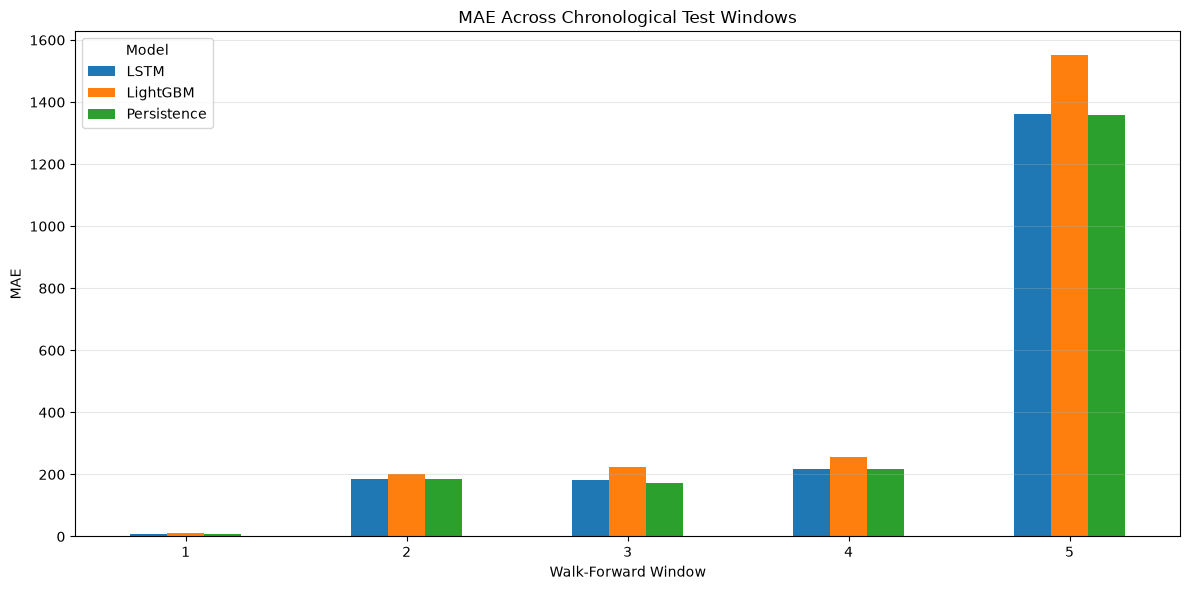

In [10]:
metric_to_plot = "MAE"

pivot = walk_forward_metrics.pivot(
    index="Fold",
    columns="Model",
    values=metric_to_plot
)

pivot = pivot[["LSTM", "LightGBM", "Persistence"]]

pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("MAE Across Chronological Test Windows")
plt.xlabel("Walk-Forward Window")
plt.ylabel("MAE")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
average_metrics = (
    walk_forward_metrics
    .groupby("Model")[["MAE", "RMSE", "MAPE (%)", "R2"]]
    .mean()
)

display(average_metrics.round(4))

,MAE,RMSE,MAPE (%),R2
Model,,,,
LSTM,390.9510,587.7164,2.6905,0.9822
LightGBM,448.5245,645.1438,3.1932,0.9778
Persistence,388.4467,585.4124,2.6413,0.9824


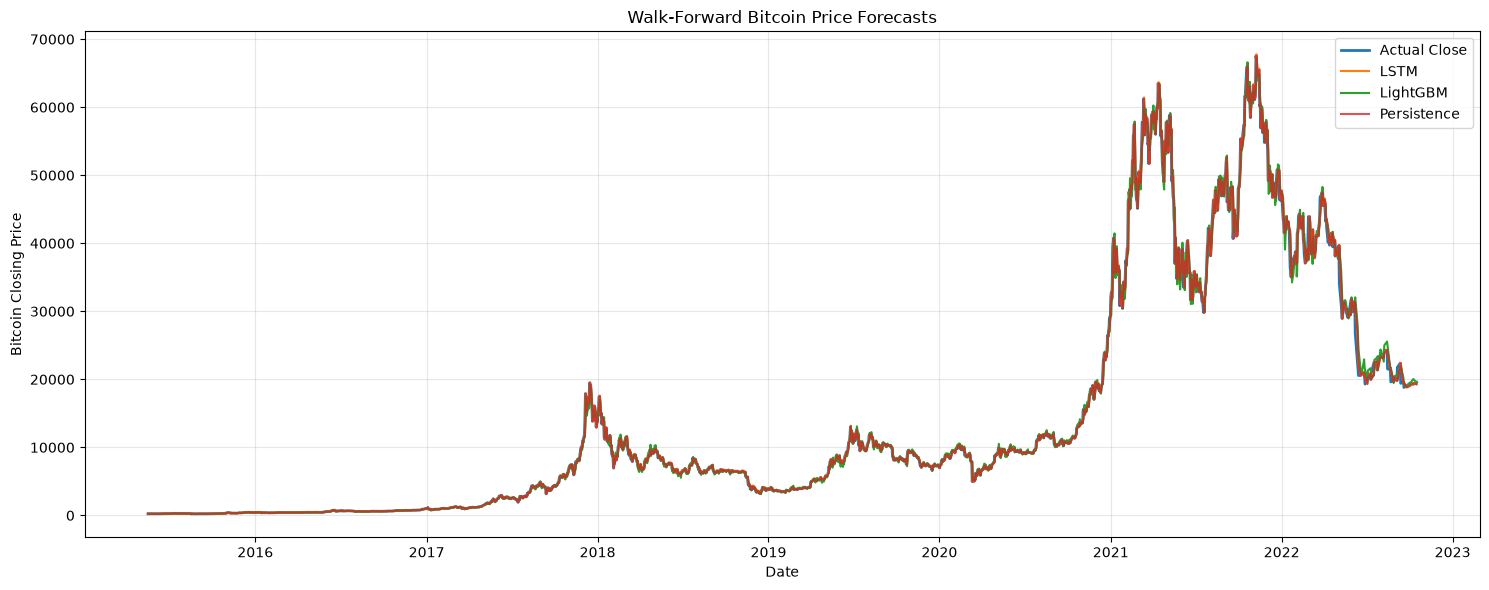

In [12]:
plt.figure(figsize=(15, 6))

plt.plot(
    walk_forward_predictions["Date"],
    walk_forward_predictions["Actual_Close"],
    label="Actual Close",
    linewidth=2
)

plt.plot(
    walk_forward_predictions["Date"],
    walk_forward_predictions["LSTM_Prediction"],
    label="LSTM"
)

plt.plot(
    walk_forward_predictions["Date"],
    walk_forward_predictions["LightGBM_Prediction"],
    label="LightGBM"
)

plt.plot(
    walk_forward_predictions["Date"],
    walk_forward_predictions["Persistence_Prediction"],
    label="Persistence",
    alpha=0.8
)

plt.title("Walk-Forward Bitcoin Price Forecasts")
plt.xlabel("Date")
plt.ylabel("Bitcoin Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

walk_forward_predictions.to_csv(
    RESULTS_PATH / "walk_forward_predictions.csv",
    index=False
)

walk_forward_metrics.to_csv(
    RESULTS_PATH / "walk_forward_metrics_by_window.csv",
    index=False
)

average_metrics.to_csv(
    RESULTS_PATH / "walk_forward_average_metrics.csv"
)

print("Walk-forward evaluation saved successfully.")

Walk-forward evaluation saved successfully.


## 9. Walk-Forward Evaluation: Results and Discussion

### 9.1 Overall performance

The walk-forward experiment evaluated LSTM, LightGBM, and a persistence baseline across five chronological test windows. The reported average metrics were:

| Metric | LSTM | LightGBM | Persistence |
|---|---:|---:|---:|
| MAE | 390.95 | 448.52 | 388.45 |
| RMSE | 587.72 | 645.14 | 585.41 |
| MAPE | 2.69% | 3.19% | 2.64% |
| R² | 0.9822 | 0.9778 | 0.9824 |

LSTM outperformed LightGBM across all four aggregate metrics. However, persistence achieved marginally lower MAE and RMSE than LSTM and also had the lowest MAPE and highest R². Therefore, the results do not demonstrate a consistent overall advantage for the machine-learning models over the persistence baseline.

### 9.2 Performance across chronological windows

The per-window results reveal changes in model performance over time. Persistence achieved the lowest MAE in Windows 1, 3, 4, and 5, whereas LSTM achieved the lowest MAE in Window 2. LightGBM had the highest MAE in all five windows.

The fifth window produced substantially larger absolute errors than the earlier windows. This illustrates why model performance should be evaluated across multiple historical periods rather than inferred from a single test split. Absolute errors depend partly on the price scale, while percentage-based metrics provide a complementary view of relative error.

### 9.3 Research implications

The walk-forward analysis strengthens the project by testing the models across several successive historical periods. It indicates that LSTM is a stronger candidate than LightGBM under the configurations evaluated, but that neither model consistently improves on the persistence benchmark.

These findings motivate further investigation into return predictability, changing market conditions, and the stability of forecasting performance. They should not be interpreted as proof that the same ranking will persist in future cryptocurrency markets.

### 9.4 Limitations

The experiment uses five chronological windows from a single Bitcoin dataset. LSTM is trained for a fixed 20 epochs in each window, and the model configurations are not exhaustively optimized using separate validation periods within every fold. The reported aggregate metrics are averages of window-specific metrics rather than metrics computed over all pooled predictions.

Further work could use nested chronological validation, multiple forecast horizons, and paired uncertainty analysis across the walk-forward predictions. These extensions would provide a more rigorous assessment of generalization and the practical value of the machine-learning models.

In [14]:
pooled_results = []

for model_name, column in [
    ("LSTM", "LSTM_Prediction"),
    ("LightGBM", "LightGBM_Prediction"),
    ("Persistence", "Persistence_Prediction")
]:
    actual = walk_forward_predictions["Actual_Close"]
    predicted = walk_forward_predictions[column]

    pooled_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100,
        "R2": r2_score(actual, predicted)
    })

pooled_metrics_df = pd.DataFrame(pooled_results).set_index("Model")

display(pooled_metrics_df.round(4))

pooled_metrics_df.to_csv(
    RESULTS_PATH / "walk_forward_pooled_metrics.csv"
)

,MAE,RMSE,MAPE (%),R2
Model,,,,
LSTM,390.9510,883.0871,2.6905,0.9970
LightGBM,448.5245,967.0772,3.1932,0.9964
Persistence,388.4467,880.6653,2.6413,0.9970
